# Liquidity Absorption 04 — What happens between entry and exit?

**Outcome-conditioned intratrade anatomy, not a new alpha signal or validated explanation.**

Primary cohort: A03d `VD18_VOL_FIXED`, **240-minute** taker entry, the same 452 A02 candidate IDs. Compare TARGET vs STOP vs TIMEOUT, but only among positions still open at exact causal **1, 5, 15, 30 and 60-minute landmarks** after the completed signal candle. Minute features use only fully closed one-minute UM futures klines, with taker-buy quote volume as an *aggressive flow proxy*. No future market information enters the feature vector. Subsequent outcome is joined for *descriptive comparison only*.

Do **not** equate any winner/loss feature difference with a causal reason or a deployable filter. Target distance, sigma and stop geometry may explain much of the separation; only later held-out data can support prediction. No new tick archives; existing `BTCUSDT_um_1m.parquet` / `ETHUSDT_um_1m.parquet` are read once each.


In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Image
REPO=Path.cwd().resolve()
while REPO!=REPO.parent and not (REPO/'src'/'data_engineering').is_dir():
    REPO=REPO.parent
assert (REPO/'src'/'data_engineering').is_dir(), 'Open Jupyter within repo'
if str(REPO) not in sys.path:sys.path.insert(0,str(REPO))
from src.data_engineering.modeling.liquidity_absorption_stage_a import binance_root
from src.data_engineering.modeling.liquidity_absorption_stage_a04 import VERSION,Config,run
assert VERSION=='LA-A04-0.1.1', 'git pull and restart kernel'
print('A04',VERSION)
r=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-p','test_liquidity_absorption_stage_a04.py','-q'],cwd=REPO,capture_output=True,text=True)
print(r.stdout[-3000:],r.stderr[-3000:]);assert r.returncode==0, 'A04 synthetic regression tests failed'
FUTURES_ROOT=binance_root(REPO)
OUT=REPO/'notebooks'/'Liquidity_Absorption'/'04'
print('Futures archive',FUTURES_ROOT)


A04 LA-A04-0.1.1
 D:\Projects\deribit_market_data\src\data_engineering\modeling\liquidity_absorption_stage_a04.py:84: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  return z.set_index("close_ms", drop=False, verify_integrity=True).sort_index()
D:\Projects\deribit_market_data\src\data_engineering\modeling\liquidity_absorption_stage_a04.py:84: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  return z.set_index("close_ms", drop=False, verify_integrity=True).sort_index()
----------------------------------------------------------------------
Ran 16 tests in 0.132s

OK

Futures archive D:\MarketData\Binance


In [2]:
report=run(REPO,FUTURES_ROOT,OUT,Config())
display(report)


{'version': 'LA-A04-0.1.1',
 'parent': 'LA-A03d-0.1.0',
 'configuration': {'hold_minutes': 240,
  'entry_kind': 'TAKER_FIRST_POST_SIGNAL',
  'model_mode': 'VD18_VOL_FIXED',
  'landmarks_min': (1, 5, 15, 30, 60),
  'history_minutes': 30},
 'original_candidates': 452,
 'closed_primary': 414,
 'censored_primary': 1,
 'landmarks': 2260,
 'usable_risk_set_landmarks': 1691,
 'missing_minute_windows': 0,
 'status': 'EXPLORATORY_OUTCOME_CONDITIONED_NOT_CAUSAL_NOT_PREDICTIVE'}

## Outcome cohort and censoring

First examine TARGET, STOP, TIMEOUT, skipped and censored events separately. The trade-entry/exit labels come from the *frozen A03d* 240-minute risk policy, not a re-optimized strategy. The cumulative curves retain the 452-event denominator, and censored trades are not invented wins or losses.


Primary 240m outcome distribution:


,symbol,reason,n
0,BTCUSDT,CENSORED_TAPE_END,1
1,BTCUSDT,NO_STRUCTURAL_TARGET,16
2,BTCUSDT,STOP,96
3,BTCUSDT,TARGET,50
4,BTCUSDT,TIMEOUT,49
5,ETHUSDT,NO_STRUCTURAL_TARGET,21
6,ETHUSDT,STOP,106
7,ETHUSDT,TARGET,69
8,ETHUSDT,TIMEOUT,44


,symbol,horizon_min,all_signals,entered,completed_by_h,n_target,fraction_original_target,n_stop,fraction_original_stop,n_timeout,fraction_original_timeout
12,ALL,5,452,415,13,8,0.017699,5,0.011062,0,0.00000
13,ALL,15,452,415,60,23,0.050885,37,0.081858,0,0.00000
14,ALL,30,452,415,111,41,0.090708,70,0.154867,0,0.00000
15,ALL,60,452,415,192,70,0.154867,122,0.269912,0,0.00000
16,ALL,120,452,415,263,95,0.210177,168,0.371681,0,0.00000
17,ALL,240,452,415,363,119,0.263274,202,0.446903,42,0.09292


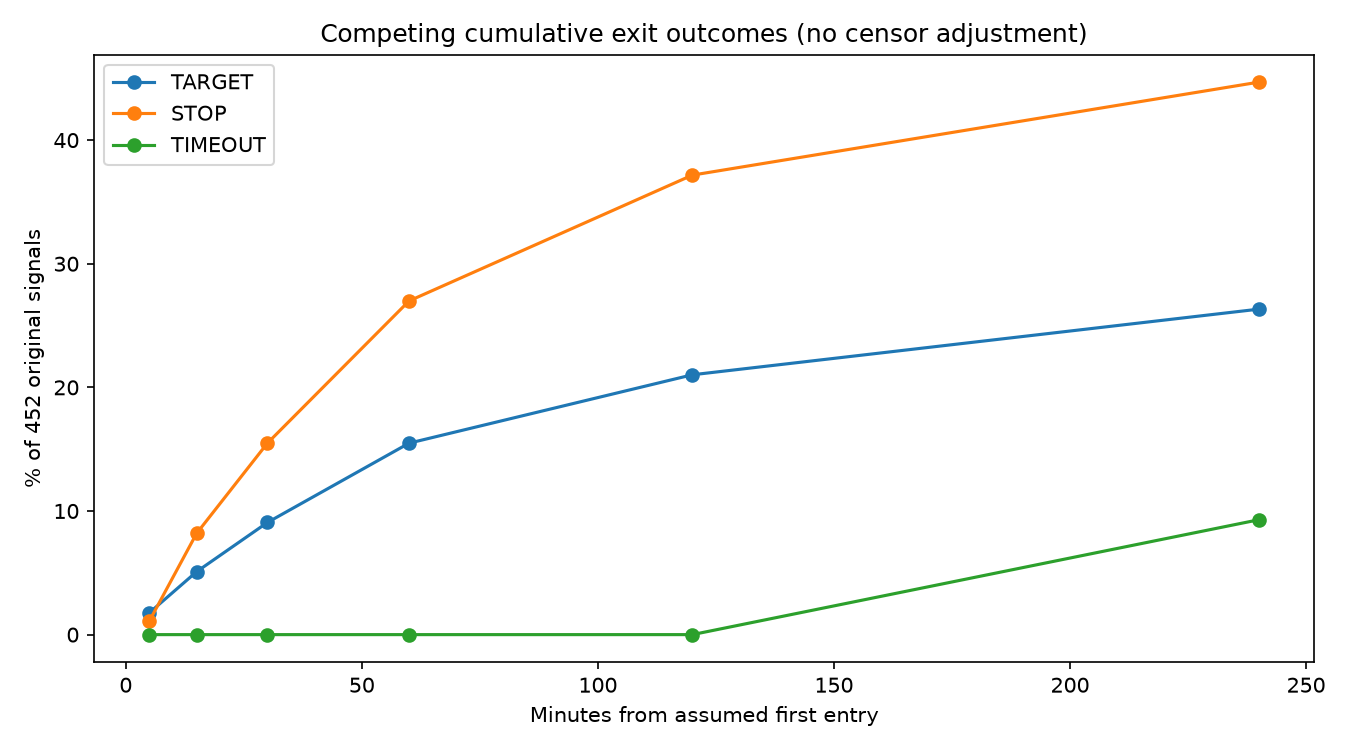

In [3]:
events=pd.read_csv(OUT/'04_primary_event_outcomes.csv')
exits=pd.read_csv(OUT/'04_competing_exits.csv')
print('Primary 240m outcome distribution:')
display(events.groupby(['symbol','reason']).size().rename('n').reset_index())
display(exits.query('symbol=="ALL"'))
display(Image(filename=str(OUT/'04_competing_exits.png')))


## At-risk intratrade landmarks

Features at +1/+5/+15/+30/+60 minutes use only one-minute candles *closed* by that checkpoint. A position is represented at a checkpoint only if its A03d exit occurs **strictly after** it. Show counts dropped due to earlier exits or missing minutes before discussing medians.

- **Price acceptance**: directional close return; fraction of completed bars closing on favorable side of liquidity level; early zone-retests; maximum favorable/adverse candle excursions
- **Flow**: directional taker-buy quote imbalance and its opposing-aggressor complement
- **Activity**: post-signal per-minute quote volume relative to 30 minutes known at signal
- **Geometry**: progress toward the frozen target, stop-distance R, and target distance relative to the frozen 60-minute forecast sigma

High/low-based excursions are retrospective within the completed minutes; they cannot prove the ordering of prints *within the same minute*. Aggressor imbalance is **not** order-book absorption or passive queue data.


Risk-set accounting:


observation_status,EXITED_BEFORE_LANDMARK,NOT_COMPLETED_COHORT,PRESENT
landmark_min,,,
1,3,38,411
5,13,38,401
15,60,38,354
30,111,38,303
60,192,38,222


Causal checkpoint feature summaries by BTC/ETH and eventual outcome:


,symbol,landmark_min,eventual_outcome,n_at_risk,median_signed_return_bp,median_max_adverse_bp,median_flow_alignment,median_quote_activity_vs_past30,median_level_favorable_close_share,median_zone_overlap_minute_fraction,median_target_over_sigma60
0,BTCUSDT,1,STOP,96,0.008,-1.698,-0.022,0.618,1.000,0.000,2.325
1,BTCUSDT,1,TARGET,49,-0.012,-1.825,0.056,0.607,1.000,0.000,1.055
2,BTCUSDT,1,TIMEOUT,49,0.125,-1.520,0.050,0.627,1.000,1.000,4.273
3,BTCUSDT,5,STOP,94,0.162,-4.596,-0.045,0.728,1.000,0.400,2.359
4,BTCUSDT,5,TARGET,46,-0.535,-3.701,-0.023,0.842,1.000,0.400,1.076
5,BTCUSDT,5,TIMEOUT,49,0.616,-3.735,-0.051,0.849,1.000,0.400,4.273
6,BTCUSDT,15,STOP,79,-0.065,-8.539,0.006,0.847,0.933,0.267,2.348
7,BTCUSDT,15,TARGET,38,7.968,-7.221,0.074,0.872,0.900,0.367,1.315
8,BTCUSDT,15,TIMEOUT,49,3.229,-5.988,-0.007,0.845,0.933,0.267,4.273
9,BTCUSDT,30,STOP,67,-4.284,-12.497,0.007,0.922,0.833,0.200,2.420


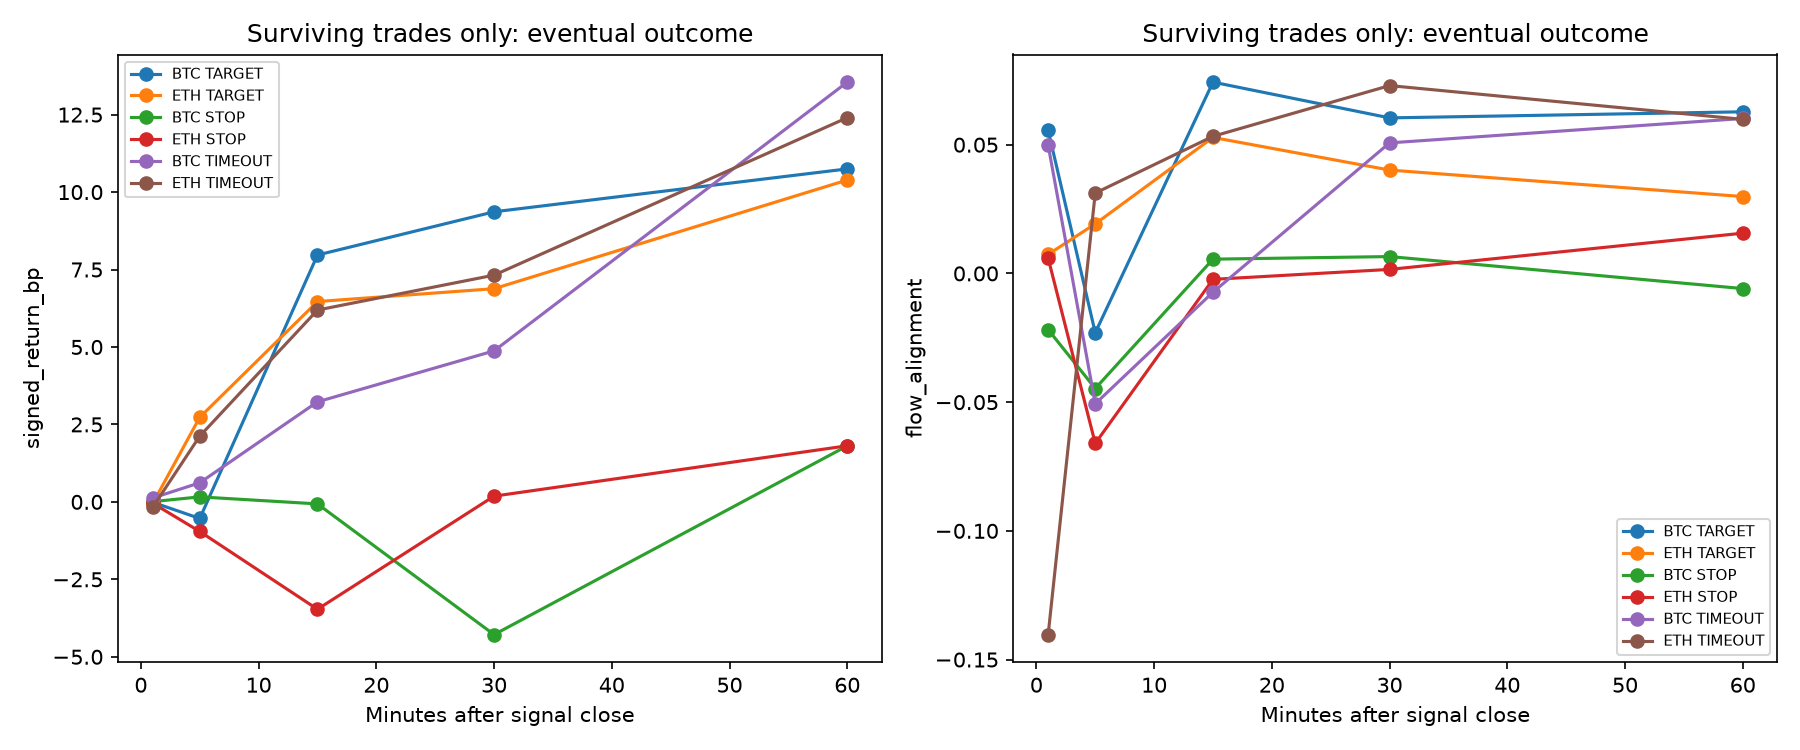

In [4]:
panel=pd.read_csv(OUT/'04_landmark_panel.csv')
summary=pd.read_csv(OUT/'04_landmark_summary.csv')
print('Risk-set accounting:')
display(panel.groupby(['landmark_min','observation_status']).size().rename('n').unstack(fill_value=0))
print('Causal checkpoint feature summaries by BTC/ETH and eventual outcome:')
cols=['symbol','landmark_min','eventual_outcome','n_at_risk','median_signed_return_bp','median_max_adverse_bp','median_flow_alignment','median_quote_activity_vs_past30','median_level_favorable_close_share','median_zone_overlap_minute_fraction','median_target_over_sigma60']
display(summary[cols].round(3))
display(Image(filename=str(OUT/'04_landmark_features.png')))


## Research interpretation / next decision

Differences visible at +5m or +15m may motivate frozen continuation features. They are **not** an independently tested signal. Keep symbol, direction, structural target type and target/sigma ratio visible as confounders. Outcomes depend heavily on barrier distance and the 240m time limit. Use time-blocked prospective evaluation **after** freezing any rule. Historical July–September 2026 is already inspected. This notebook does not edit A02/A03/VD18 or collectors and never requires tick files.
